# Bayesian Model Implementation – Cloud Cost Data (GCP)
**Member 3.** Models, priors, sampling and diagnostics only (no forecasting or optimisation).

## 0. Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import pymc as pm, arviz as az
import os
os.environ["PYTENSOR_FLAGS"] = "cxx="

import pymc as pm
import arviz as az
import pytensor
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-darkgrid")
print("PyMC", pm.__version__, "| ArviZ", az.__version__)

PyMC 6.3.1 | ArviZ 1.3.0


## 1. Data loading and integrity checks

In [2]:
df = pd.read_excel("gcp_final_approved_dataset.xlsx")
df.columns = ["resource_id","service","usage_qty","usage_unit","region","cpu","mem",
              "net_in","net_out","start","end","price_usd","cost_usd","cost_usd_rounded","cost_inr"]

print("rows, cols:", df.shape, "| missing values:", int(df.isna().sum().sum()))
print("max |qty*price - cost|        :", round(float((df.usage_qty*df.price_usd - df.cost_usd).abs().max()), 3))
print("INR / rounded USD (min, max)  :", (df.cost_inr/df.cost_usd_rounded).agg(["min","max"]).tolist())
print("unique resource IDs           :", df.resource_id.nunique())
print("correlation of cost with CPU / memory:",
      df[["cost_usd","cpu","mem"]].corr().loc["cost_usd",["cpu","mem"]].round(3).tolist())
df.describe().T[["mean","std","min","max"]].round(2)

rows, cols: (1000, 15) | missing values: 0
max |qty*price - cost|        : 0.005
INR / rounded USD (min, max)  : [83.0, 83.0]
unique resource IDs           : 1000
correlation of cost with CPU / memory: [-0.05, -0.015]


,mean,std,min,max
usage_qty,383.34353,299.815662,10.5402,998.0055
cpu,50.94368,28.824742,0.05,99.97
mem,51.62996,28.367572,0.06,99.81
net_in,51521070243.650002,28269495091.060623,1003429085.0,99837928325.0
net_out,56482322175.057999,28372839354.678116,1207921154.0,108782000000.0
start,2024-07-29 10:57:43.140000,NaN,2024-06-30 16:20:00,2024-08-29 15:21:00
end,2024-08-01 23:03:47.040000,NaN,2024-07-02 03:46:00,2024-09-03 14:19:00
price_usd,5.51504,2.539737,1.0,9.99
cost_usd,2135.21513,2080.530698,13.91,9003.65
cost_usd_rounded,2135.215,2080.553012,14.0,9004.0


## 2. Daily aggregation (input to Model 1)

59 days | mean $35,777/day | sd $12,928/day


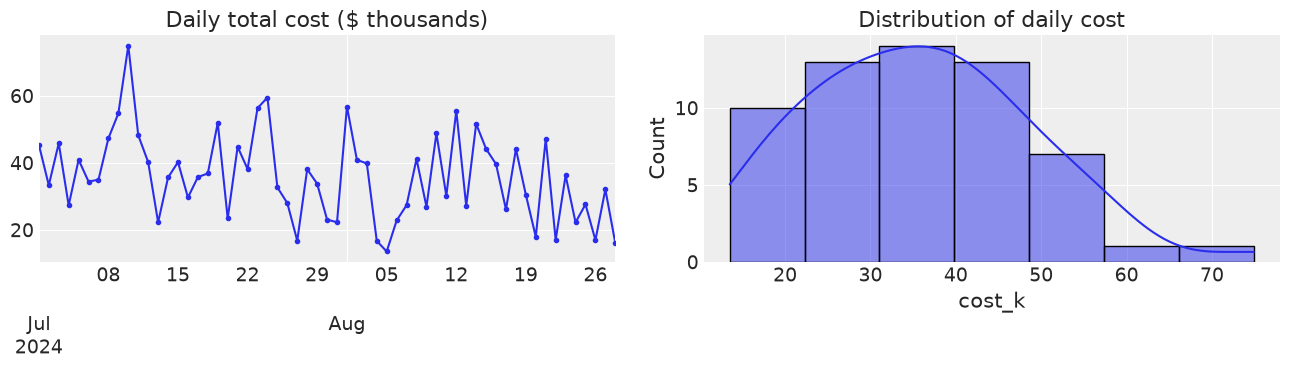

In [3]:
df["date"] = df["start"].dt.normalize()
daily = df.groupby("date").agg(cost=("cost_usd","sum"), n_records=("cost_usd","size"))
daily = daily.loc["2024-07-01":"2024-08-28"]                     # drop partial first/last days
daily = daily.reindex(pd.date_range(daily.index.min(), daily.index.max()), fill_value=0)
daily["cost_k"] = daily["cost"] / 1000                           # work in $ thousands (better sampler scaling)

print(f"{len(daily)} days | mean ${daily.cost.mean():,.0f}/day | sd ${daily.cost.std():,.0f}/day")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
daily["cost_k"].plot(ax=ax[0], marker="o", ms=3); ax[0].set_title("Daily total cost ($ thousands)")
sns.histplot(daily["cost_k"], kde=True, ax=ax[1]); ax[1].set_title("Distribution of daily cost")
plt.tight_layout(); plt.show()

## 3. Warm-up: Bayes' theorem and prior sensitivity (grid posterior for mean daily cost)

Weakly informative  N(30, 15)    posterior mean =  35.71   (sample mean = 35.78)
Flat (uniform 0-80)              posterior mean =  35.78   (sample mean = 35.78)
Strong but WRONG  N(10, 2)       posterior mean =  25.09   (sample mean = 35.78)


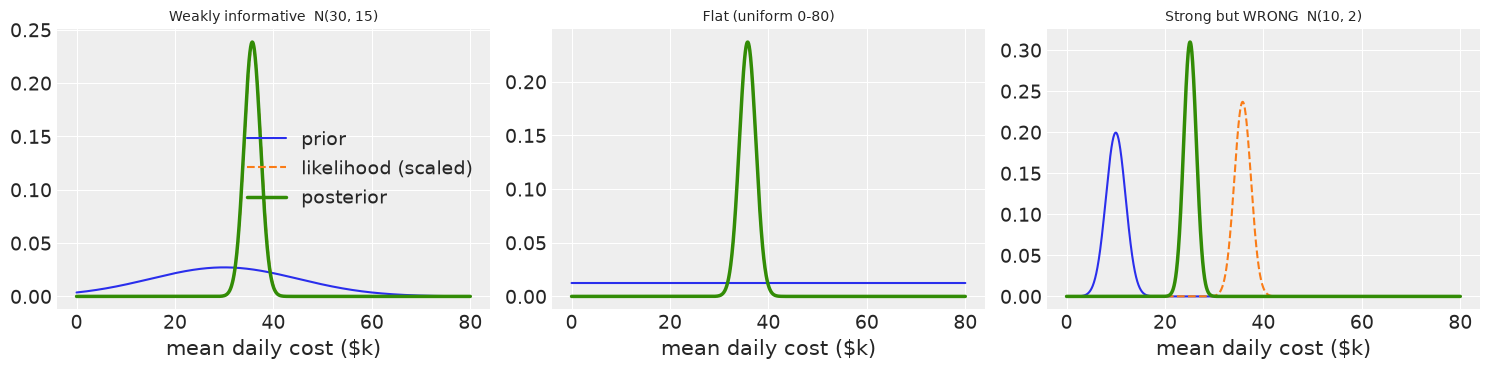

In [4]:
y = daily["cost_k"].to_numpy()
sigma_known = y.std(ddof=1)
mu_grid = np.linspace(0, 80, 2000)
dmu = mu_grid[1] - mu_grid[0]

def grid_posterior(prior_pdf):
    # log-likelihood of ALL observations at each candidate mu (independent days -> sum of logs)
    loglik = stats.norm.logpdf(y[:, None], loc=mu_grid[None, :], scale=sigma_known).sum(axis=0)
    unnorm = np.exp(loglik - loglik.max()) * prior_pdf        # likelihood x prior
    return unnorm / (unnorm.sum() * dmu), loglik              # divide by evidence -> proper density

priors = {
    "Weakly informative  N(30, 15)": stats.norm.pdf(mu_grid, 30, 15),
    "Flat (uniform 0-80)":           np.ones_like(mu_grid),
    "Strong but WRONG  N(10, 2)":    stats.norm.pdf(mu_grid, 10, 2),
}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharex=True)
for ax, (name, pr) in zip(axes, priors.items()):
    pr_n = pr / (pr.sum() * dmu)
    post, loglik = grid_posterior(pr_n)
    lik = np.exp(loglik - loglik.max()); lik = lik / (lik.sum() * dmu)
    ax.plot(mu_grid, pr_n, label="prior"); ax.plot(mu_grid, lik, "--", label="likelihood (scaled)")
    ax.plot(mu_grid, post, lw=2.5, label="posterior"); ax.set_title(name, fontsize=10); ax.set_xlabel("mean daily cost ($k)")
    mean = (mu_grid * post).sum() * dmu
    print(f"{name:32s} posterior mean = {mean:6.2f}   (sample mean = {y.mean():.2f})")
axes[0].legend(); plt.tight_layout(); plt.show()

## 4. Beta-Binomial model for the fraction of idle resources

26 idle resources out of 1000 (2.6%); mean cost idle $2,423 vs all $2,135
Uniform Beta(1,1)                        posterior mean 0.027, 94% interval [0.018, 0.037]
Mild belief ~10%: Beta(2,18)             posterior mean 0.027, 94% interval [0.019, 0.038]
Strong WRONG belief ~80%: Beta(20,5)     posterior mean 0.045, 94% interval [0.033, 0.058]


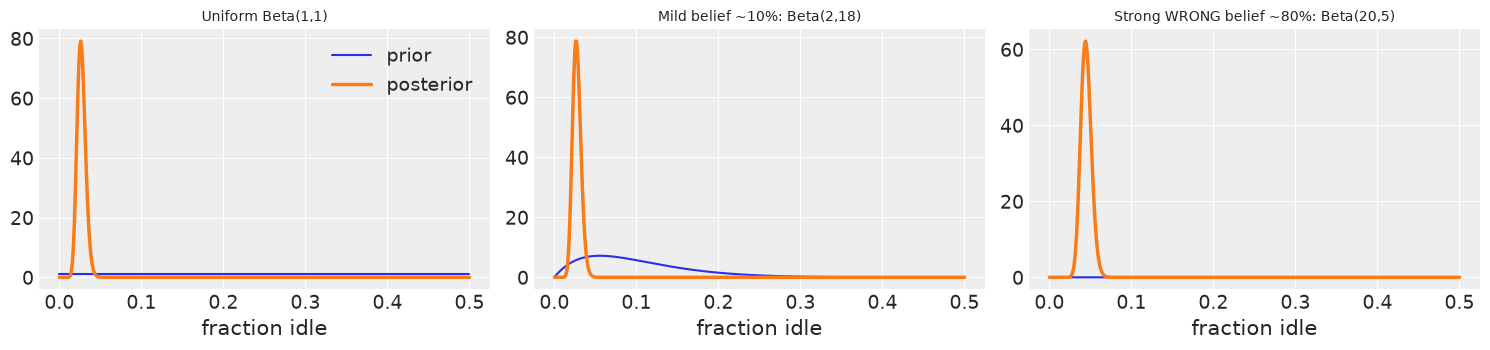

In [5]:
idle = (df.cpu < 20) & (df.mem < 20)
k, n = int(idle.sum()), len(df)
print(f"{k} idle resources out of {n} ({k/n:.1%}); mean cost idle ${df.cost_usd[idle].mean():,.0f} vs all ${df.cost_usd.mean():,.0f}")

beta_priors = {"Uniform Beta(1,1)": (1, 1), "Mild belief ~10%: Beta(2,18)": (2, 18), "Strong WRONG belief ~80%: Beta(20,5)": (20, 5)}
p = np.linspace(0, 0.5, 500)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=False)
for ax, (name, (a, b)) in zip(axes, beta_priors.items()):
    post = stats.beta(a + k, b + n - k)
    ax.plot(p, stats.beta(a, b).pdf(p), label="prior"); ax.plot(p, post.pdf(p), lw=2.5, label="posterior")
    ax.set_title(name, fontsize=10); ax.set_xlabel("fraction idle")
    lo, hi = post.interval(0.94)
    print(f"{name:40s} posterior mean {post.mean():.3f}, 94% interval [{lo:.3f}, {hi:.3f}]")
axes[0].legend(); plt.tight_layout(); plt.show()

## 5. Choice of distribution (Normal vs Student-t; log transform)

Daily total log-likelihood  Normal: -234.2 | Student-t: -234.2


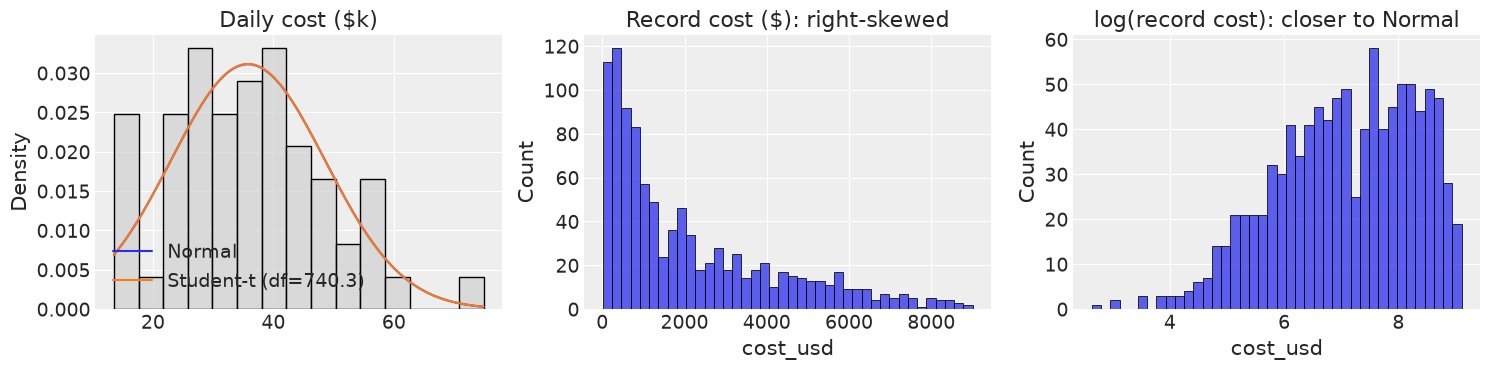

skewness raw: 1.19 | skewness log: -0.48


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
# (a) daily cost: Normal vs Student-t fit
sns.histplot(y, stat="density", bins=15, ax=ax[0], color="lightgray")
xs = np.linspace(y.min(), y.max(), 300)
nm = stats.norm.fit(y); tt = stats.t.fit(y)
ax[0].plot(xs, stats.norm.pdf(xs, *nm), label="Normal"); ax[0].plot(xs, stats.t.pdf(xs, *tt), label=f"Student-t (df={tt[0]:.1f})")
ax[0].set_title("Daily cost ($k)"); ax[0].legend()
print("Daily total log-likelihood  Normal:", stats.norm.logpdf(y, *nm).sum().round(1), "| Student-t:", stats.t.logpdf(y, *tt).sum().round(1))
# (b) raw record cost vs (c) log cost
sns.histplot(df.cost_usd, bins=40, ax=ax[1]); ax[1].set_title("Record cost ($): right-skewed")
sns.histplot(np.log(df.cost_usd), bins=40, ax=ax[2]); ax[2].set_title("log(record cost): closer to Normal")
plt.tight_layout(); plt.show()
print("skewness raw:", round(df.cost_usd.skew(), 2), "| skewness log:", round(np.log(df.cost_usd).skew(), 2))

## 6. Model 1 – Bayesian time-series model (priors, prior predictive check, sampling)

Sampling: [alpha, beta, dow_raw, nu, obs, sigma, tau_dow]


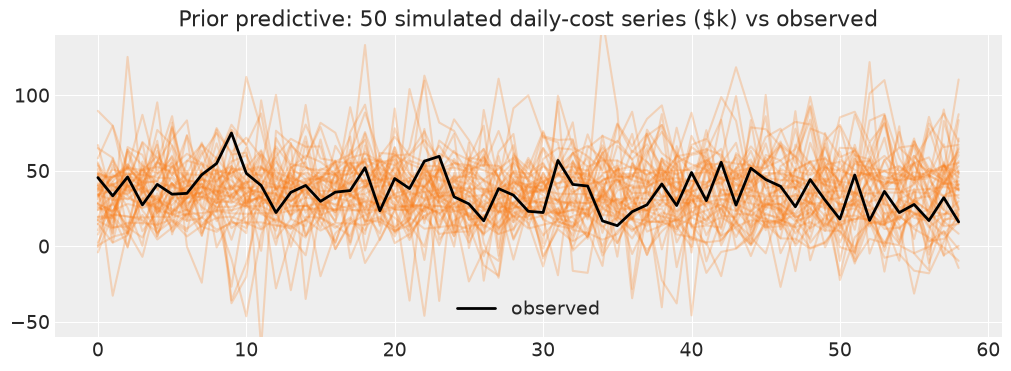

NUTS[nutpie]: [alpha, beta, tau_dow, dow_raw, sigma, nu]


Sampling: [obs]


              mean     sd eti94_lb eti94_ub ess_bulk ess_tail r_hat mcse_mean mcse_sd
alpha         0.42  0.243   -0.041     0.88     1789     2163  1.00    0.0057  0.0041
beta         -0.91   0.39     -1.6    -0.17     2057     2072  1.00    0.0087  0.0063
sigma         0.92  0.099     0.75      1.1     3709     2545  1.00    0.0016  0.0016
nu            23.5     14      5.9       56     3714     2589  1.00      0.22    0.28
tau_dow      0.198  0.158   0.0095     0.58     1337     1350  1.00    0.0039  0.0033
dow_eff[0]   0.003  0.182    -0.35      0.4     3588     2768  1.00    0.0032  0.0046
dow_eff[1]  -0.063  0.189    -0.49     0.26     3728     3135  1.00    0.0032   0.004
dow_eff[2]   0.131  0.218    -0.16     0.66     2449     2875  1.00    0.0045  0.0044
dow_eff[3]   0.047  0.184    -0.28     0.46     3253     2724  1.00    0.0034  0.0042
dow_eff[4]   0.055  0.186    -0.27     0.47     3273     3061  1.00    0.0034  0.0041
dow_eff[5]  -0.128  0.209    -0.62     0.16     2612  

In [12]:
y_mu, y_sd = y.mean(), y.std()
z = (y - y_mu) / y_sd                         # standardised daily cost
T = len(z)
t = np.arange(T) / (T - 1)                    # 0 ... 1 across the observed window
dow = daily.index.dayofweek.to_numpy()        # 0=Mon ... 6=Sun

with pm.Model(coords={"dow": np.arange(7)}) as ts_model:
    # ----- priors -----
    alpha   = pm.Normal("alpha", 0, 1)
    beta    = pm.Normal("beta", 0, 1)
    tau_dow = pm.HalfNormal("tau_dow", 0.5)
    dow_raw = pm.Normal("dow_raw", 0, 1, dims="dow")             # non-centred parametrisation
    dow_eff = pm.Deterministic("dow_eff", tau_dow * dow_raw, dims="dow")
    sigma   = pm.HalfNormal("sigma", 1)
    nu      = pm.Gamma("nu", 2, 0.1)
    # ----- likelihood -----
    mu = alpha + beta * t + dow_eff[dow]
    pm.StudentT("obs", nu=nu, mu=mu, sigma=sigma, observed=z)
with ts_model:
    prior_ts = pm.sample_prior_predictive(300, random_seed=RANDOM_SEED)

sim = prior_ts.prior_predictive["obs"].stack(s=("chain", "draw")).values   # (T, 300) in z-units
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(sim[:, :50] * y_sd + y_mu, color="C1", alpha=0.25)
ax.plot(y, color="k", lw=2, label="observed"); ax.set_ylim(-60, 140)
ax.set_title("Prior predictive: 50 simulated daily-cost series ($k) vs observed"); ax.legend(); plt.show()
#pm.model_to_graphviz(ts_model)   # optional: needs graphviz installed

with ts_model:
    idata_ts = pm.sample(draws=1000, tune=1000, chains=4, target_accept=0.9,
                         random_seed=RANDOM_SEED, idata_kwargs={"log_likelihood": True})
    pm.sample_posterior_predictive(idata_ts, extend_inferencedata=True, random_seed=RANDOM_SEED)
summary = az.summary(
    idata_ts,
    var_names=["alpha", "beta", "sigma", "nu", "tau_dow", "dow_eff"],
    ci_prob=0.94
)

print(summary.round(3))

## 7. Model 2 – Hierarchical Bayesian model by service

In [15]:
svc = df["service"].astype("category")
s_idx = svc.cat.codes.to_numpy()
svc_names = list(svc.cat.categories)
ylog = np.log(df["cost_usd"].to_numpy())

with pm.Model(coords={"service": svc_names}) as hier_model:
    mu_g  = pm.Normal("mu_g", ylog.mean(), 2)
    tau   = pm.HalfNormal("tau", 1.5)
    z_s   = pm.Normal("z_s", 0, 1, dims="service")                  # non-centred
    mu_s  = pm.Deterministic("mu_s", mu_g + tau * z_s, dims="service")
    sigma = pm.HalfNormal("sigma", 2)
    pm.Normal("obs", mu=mu_s[s_idx], sigma=sigma, observed=ylog)

    idata_h = pm.sample(1000, tune=1000, chains=4, target_accept=0.9, random_seed=RANDOM_SEED,
                        idata_kwargs={"log_likelihood": True})
    pm.sample_posterior_predictive(idata_h, extend_inferencedata=True, random_seed=RANDOM_SEED)

az.summary(idata_h, var_names=["mu_g", "tau", "sigma"], ci_prob=0.94).round(3)

NUTS[nutpie]: [mu_g, tau, z_s, sigma]


Sampling: [obs]


,mean,sd,eti94_lb,eti94_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mu_g,7.1,0.144,6.8,7.4,318,574,1.02,0.008,0.0042
tau,0.72,0.113,0.54,0.96,437,627,1.01,0.0056,0.0038
sigma,1.0152,0.0235,0.97,1.1,4668,2995,1.00,0.00034,0.00042


## 8. Model 1 posterior distributions

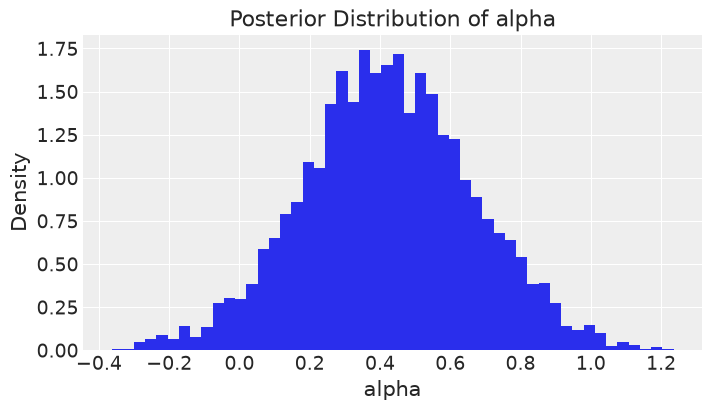

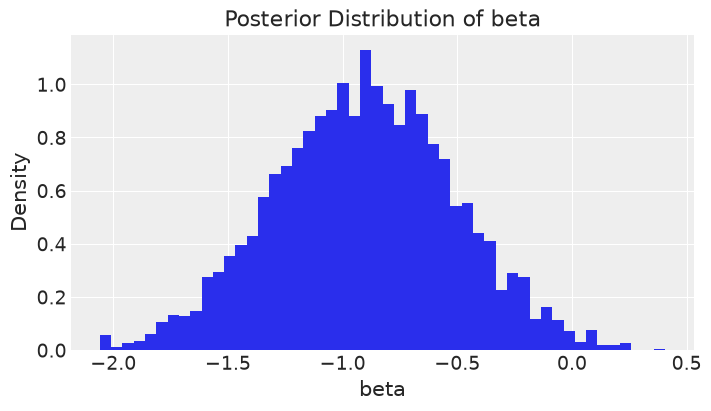

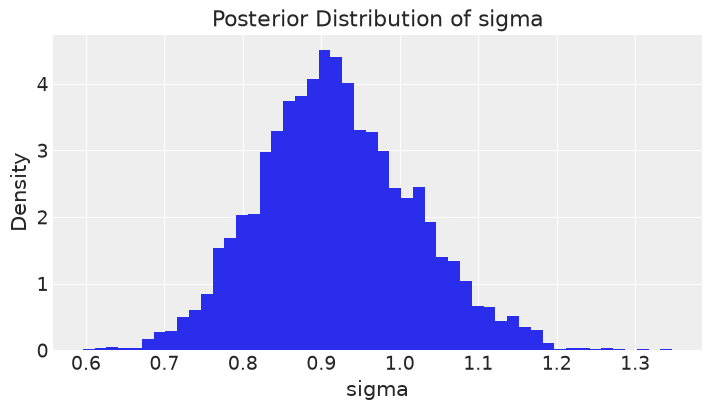

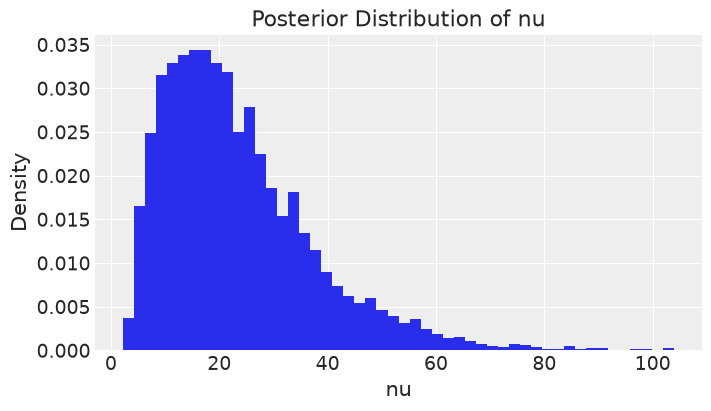

P(spend trend is increasing) = P(beta > 0) = 0.01
Implied change over the window: [-21.1  -11.56  -2.19] ($k/day, 94% interval)


In [17]:
import matplotlib.pyplot as plt
import numpy as np

# Posterior distributions
variables = ["alpha", "beta", "sigma", "nu"]

for var in variables:
    samples = idata_ts.posterior[var].values.ravel()

    plt.figure(figsize=(7, 4))
    plt.hist(samples, bins=50, density=True)
    plt.title(f"Posterior Distribution of {var}")
    plt.xlabel(var)
    plt.ylabel("Density")
    plt.show()

# Probability that spending trend is increasing
beta_post = idata_ts.posterior["beta"].values.ravel()

print(f"P(spend trend is increasing) = P(beta > 0) = {(beta_post > 0).mean():.2f}")

# 94% credible interval for implied change
beta_change = beta_post * y_sd
interval = np.percentile(beta_change, [3, 50, 97]).round(2)

print(f"Implied change over the window: {interval} ($k/day, 94% interval)")

## 9. Model 2 posterior: mean cost per record by service

In [18]:
post_h = idata_h.posterior
mu_s_draws = post_h["mu_s"].stack(s=("chain", "draw")).transpose("service", "s").values   # (25, S)
sig_draws  = post_h["sigma"].stack(s=("chain", "draw")).values                              # (S,)

# model-implied mean cost per record: E[cost] = exp(mu + sigma^2/2) for a lognormal
mean_cost = np.exp(mu_s_draws + sig_draws[None, :]**2 / 2)
obs_mean = df.groupby("service")["cost_usd"].mean().reindex(svc_names).to_numpy()

res = pd.DataFrame({
    "post_mean_cost":  mean_cost.mean(axis=1),
    "hdi3":  np.percentile(mean_cost, 3, axis=1),
    "hdi97": np.percentile(mean_cost, 97, axis=1),
    "observed_mean": obs_mean,
    "n": df.groupby("service").size().reindex(svc_names).to_numpy(),
}, index=svc_names).sort_values("post_mean_cost", ascending=False).round(0)
res

,post_mean_cost,hdi3,hdi97,observed_mean,n
Cloud NAT,4011.0,2849.0,5445.0,3389.0,35
Cloud Data Fusion,3793.0,2573.0,5404.0,3351.0,25
Cloud Load Balancing,3534.0,2479.0,4946.0,3089.0,32
Container Registry,3402.0,2398.0,4707.0,2846.0,30
Cloud CDN,3341.0,2542.0,4293.0,2773.0,51
Cloud SQL,3164.0,2253.0,4330.0,2891.0,35
Cloud Build,3123.0,2361.0,4081.0,2816.0,48
Cloud VPN,3115.0,2268.0,4185.0,2720.0,37
Cloud Memorystore,3016.0,2215.0,4009.0,2684.0,39
Cloud VPC,3004.0,2194.0,4001.0,2582.0,38


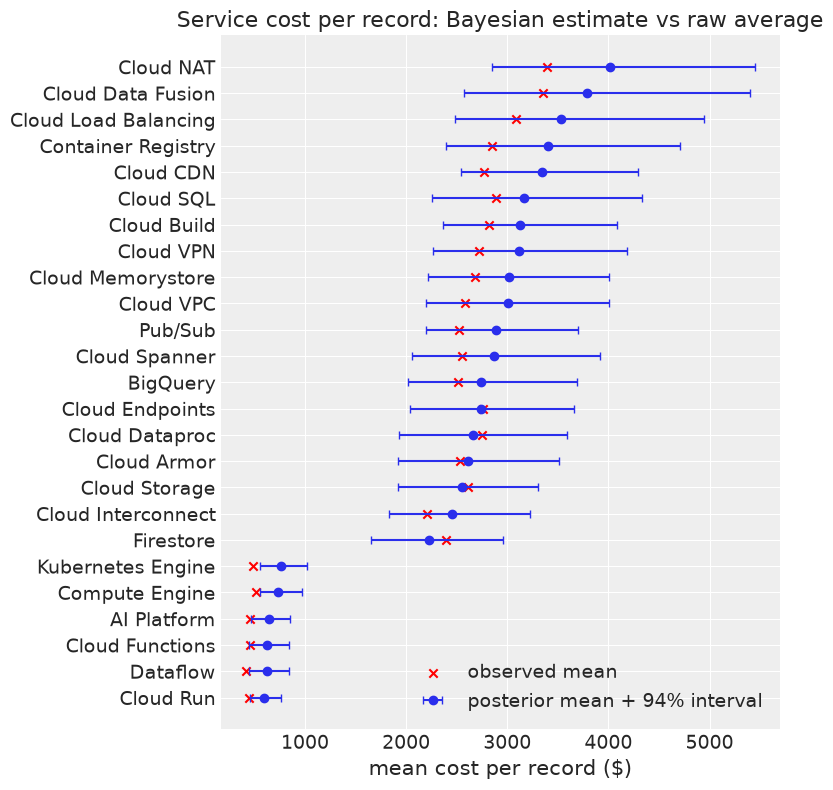

In [19]:
fig, ax = plt.subplots(figsize=(8, 8))
r = res.iloc[::-1]
ax.errorbar(r.post_mean_cost, range(len(r)), xerr=[r.post_mean_cost - r.hdi3, r.hdi97 - r.post_mean_cost], fmt="o", capsize=3, label="posterior mean + 94% interval")
ax.scatter(r.observed_mean, range(len(r)), marker="x", color="red", label="observed mean")
ax.set_yticks(range(len(r))); ax.set_yticklabels(r.index); ax.set_xlabel("mean cost per record ($)")
ax.legend(); ax.set_title("Service cost per record: Bayesian estimate vs raw average"); plt.tight_layout(); plt.show()

## 10. Convergence diagnostics

In [20]:
def diagnose(idata, var_names, name):
    summ = az.summary(idata, var_names=var_names, round_to=3)
    n_div = int(idata.sample_stats["diverging"].sum())
    bfmi = az.bfmi(idata)
    print(f"=== {name} ===")
    print(f"max R-hat      : {summ['r_hat'].max():.3f}  (want < 1.01)")
    print(f"min ESS bulk   : {summ['ess_bulk'].min():.0f}  (want > 400)")
    print(f"min ESS tail   : {summ['ess_tail'].min():.0f}  (want > 400)")
    print(f"divergences    : {n_div}  (want 0)")
    print(f"BFMI per chain : {np.round(bfmi, 2)}  (want > 0.3)")
    return summ

s1 = diagnose(idata_ts, ["alpha", "beta", "sigma", "nu", "tau_dow", "dow_eff"], "Model 1: time-series")
s2 = diagnose(idata_h,  ["mu_g", "tau", "sigma", "mu_s"], "Model 2: hierarchical")

=== Model 1: time-series ===
max R-hat      : 1.004  (want < 1.01)
min ESS bulk   : 1337  (want > 400)
min ESS tail   : 1350  (want > 400)
divergences    : 0  (want 0)
BFMI per chain : <xarray.DataTree 'sample_stats'>
Group: /
    Dimensions:  (chain: 4)
    Coordinates:
      * chain    (chain) int64 32B 0 1 2 3
    Data variables:
        energy   (chain) float64 32B 0.85 0.88 0.93 0.87  (want > 0.3)
=== Model 2: hierarchical ===
max R-hat      : 1.017  (want < 1.01)
min ESS bulk   : 318  (want > 400)
min ESS tail   : 575  (want > 400)
divergences    : 0  (want 0)
BFMI per chain : <xarray.DataTree 'sample_stats'>
Group: /
    Dimensions:  (chain: 4)
    Coordinates:
      * chain    (chain) int64 32B 0 1 2 3
    Data variables:
        energy   (chain) float64 32B 0.72 0.72 0.73 0.7  (want > 0.3)


## 11. Trace, rank and energy plots

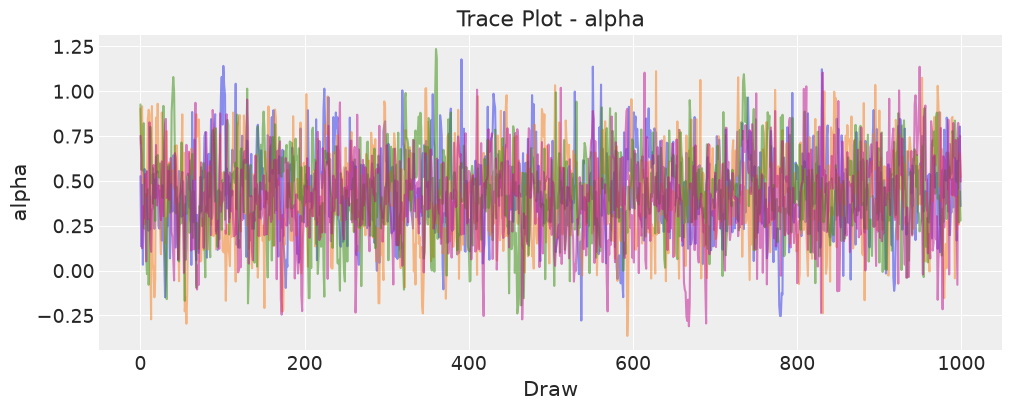

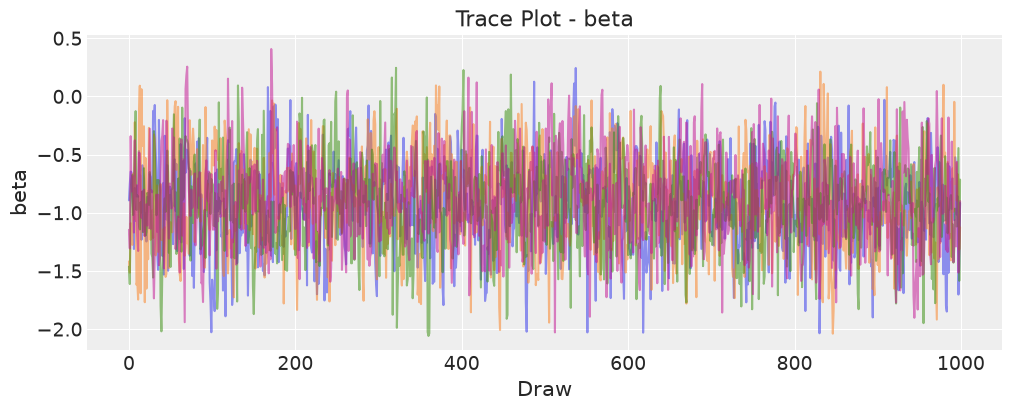

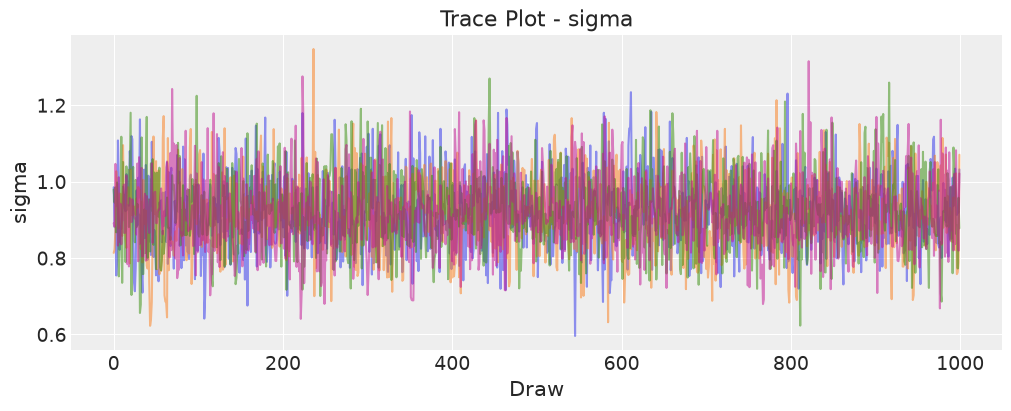

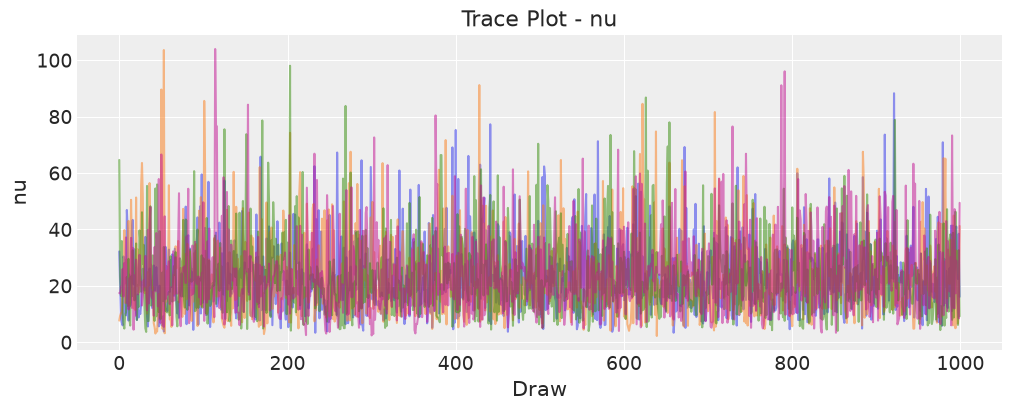

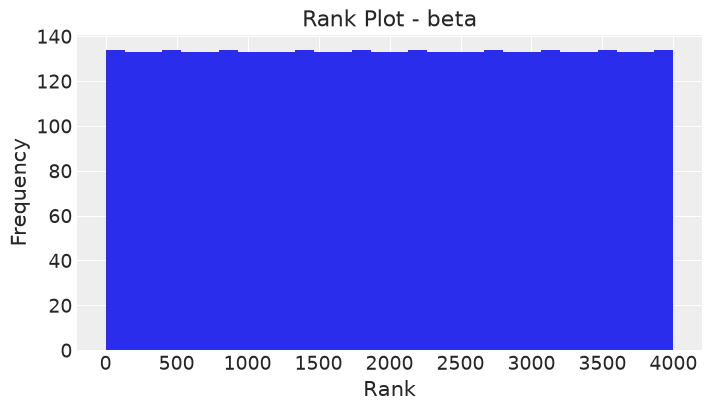

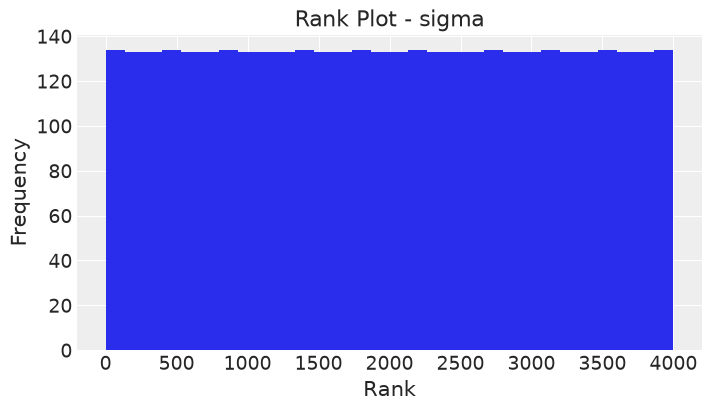

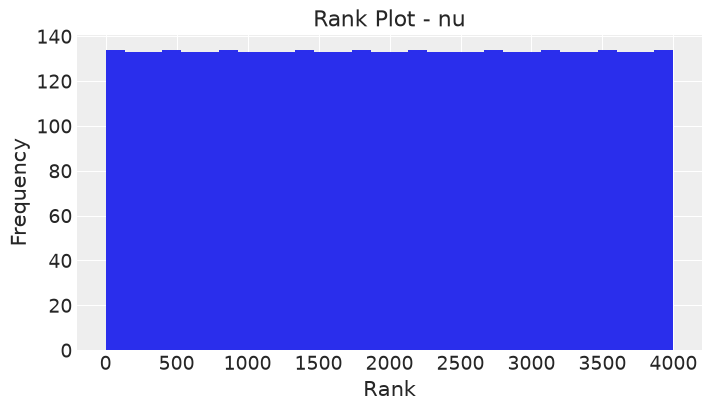

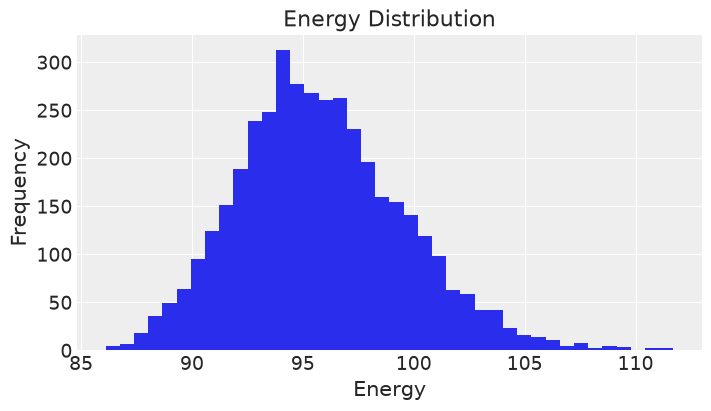

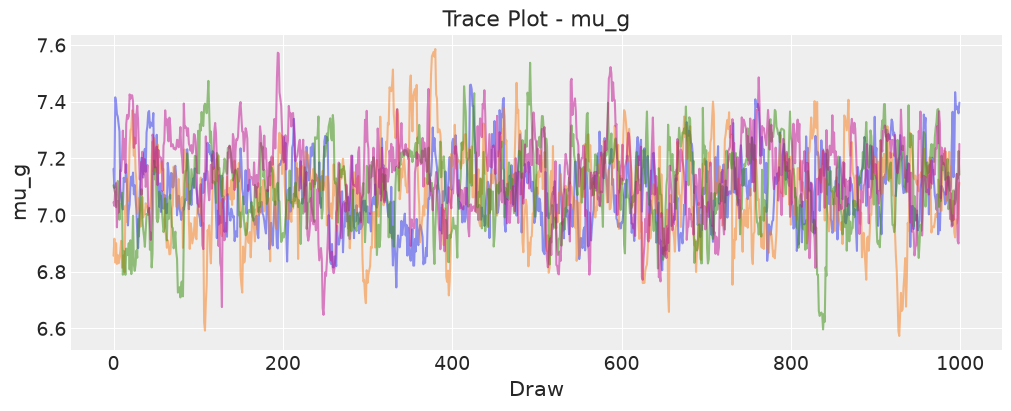

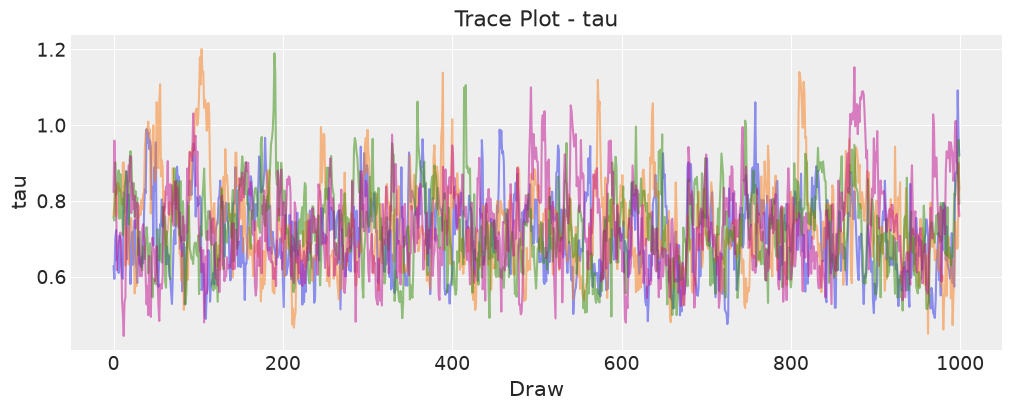

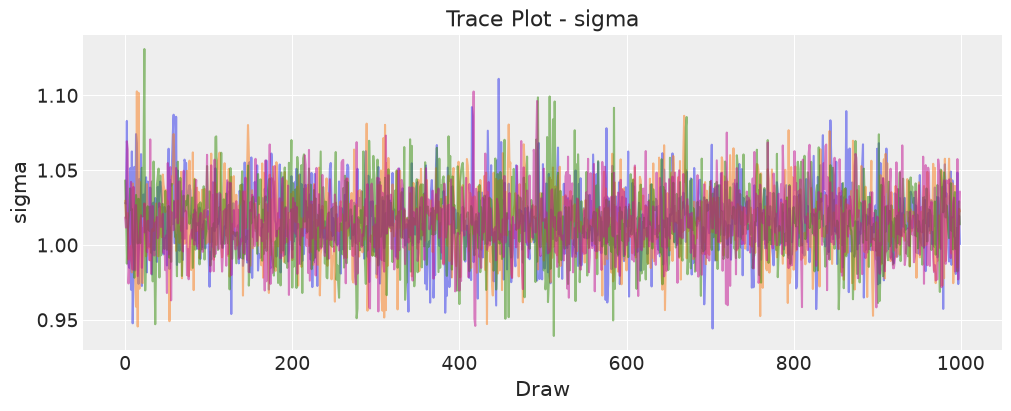

In [22]:
import matplotlib.pyplot as plt
import numpy as np

# --------------------------------------------------
# 1. Trace plots for alpha, beta, sigma and nu
# --------------------------------------------------

variables = ["alpha", "beta", "sigma", "nu"]

for var in variables:
    samples = idata_ts.posterior[var].values

    # Combine chains
    chains = samples.shape[0]
    draws = samples.shape[1]

    plt.figure(figsize=(10, 4))

    for chain in range(chains):
        plt.plot(samples[chain], alpha=0.5)

    plt.title(f"Trace Plot - {var}")
    plt.xlabel("Draw")
    plt.ylabel(var)
    plt.show()


# --------------------------------------------------
# 2. Rank-style diagnostic for beta, sigma and nu
# --------------------------------------------------

for var in ["beta", "sigma", "nu"]:
    samples = idata_ts.posterior[var].values.flatten()

    ranks = np.argsort(np.argsort(samples))

    plt.figure(figsize=(7, 4))
    plt.hist(ranks, bins=30)
    plt.title(f"Rank Plot - {var}")
    plt.xlabel("Rank")
    plt.ylabel("Frequency")
    plt.show()


# --------------------------------------------------
# 3. Energy plot
# --------------------------------------------------

if "energy" in idata_ts.sample_stats:
    energy = idata_ts.sample_stats["energy"].values.flatten()

    plt.figure(figsize=(7, 4))
    plt.hist(energy, bins=40)
    plt.title("Energy Distribution")
    plt.xlabel("Energy")
    plt.ylabel("Frequency")
    plt.show()


# --------------------------------------------------
# 4. Trace plots for hierarchical model
# --------------------------------------------------

variables_h = ["mu_g", "tau", "sigma"]

for var in variables_h:
    samples = idata_h.posterior[var].values

    plt.figure(figsize=(10, 4))

    for chain in range(samples.shape[0]):
        plt.plot(samples[chain].ravel(), alpha=0.5)

    plt.title(f"Trace Plot - {var}")
    plt.xlabel("Draw")
    plt.ylabel(var)
    plt.show()

## 12. Posterior predictive checks

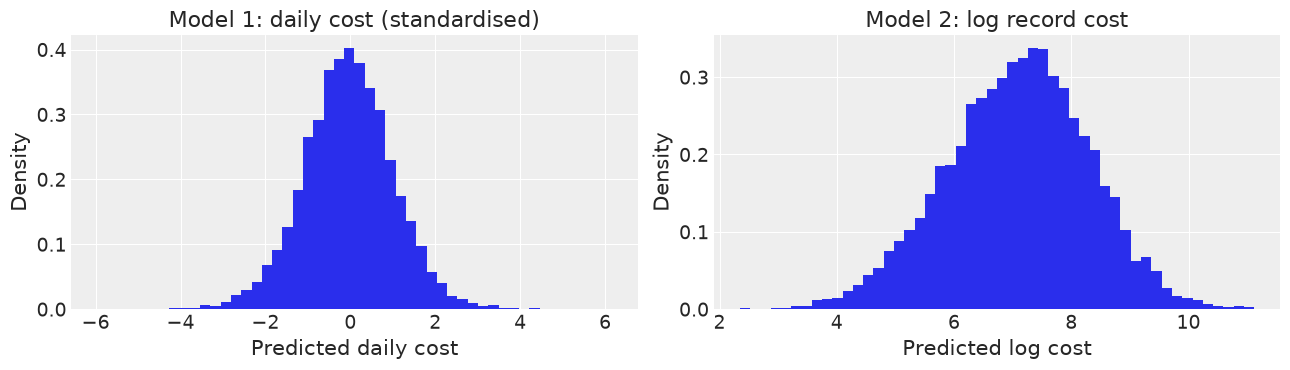

In [23]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))

# Model 1: daily cost
ppc_ts = idata_ts.posterior_predictive

# Get the first posterior predictive variable
var_ts = list(ppc_ts.data_vars)[0]
samples_ts = ppc_ts[var_ts].values.flatten()

# Plot a manageable number of samples
samples_ts = samples_ts[:10000]

ax[0].hist(samples_ts, bins=50, density=True)
ax[0].set_title("Model 1: daily cost (standardised)")
ax[0].set_xlabel("Predicted daily cost")
ax[0].set_ylabel("Density")


# Model 2: log record cost
ppc_h = idata_h.posterior_predictive

# Get the first posterior predictive variable
var_h = list(ppc_h.data_vars)[0]
samples_h = ppc_h[var_h].values.flatten()

samples_h = samples_h[:10000]

ax[1].hist(samples_h, bins=50, density=True)
ax[1].set_title("Model 2: log record cost")
ax[1].set_xlabel("Predicted log cost")
ax[1].set_ylabel("Density")

plt.tight_layout()
plt.show()